# Solutions to notebook 3: Smoothness and spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/03_smoothness_and_spectral_accuracy.ipynb)

Worked solutions to the exercises at the end of [notebook 3](../notebooks/03_smoothness_and_spectral_accuracy.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# fft_derivative(v, order) from notebook 2
def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v on the grid x_j = 2πj/N."""
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0                                     # the Nyquist mode, see notebook 2
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

# functions from notebook 3
def fourier_grid(N):
    """Equispaced periodic grid on [0, 2*pi): x_j = 2*pi*j/N, j = 0..N-1."""
    return 2 * np.pi * np.arange(N) / N

def fourier_coefficients(u, M=4096):
    """Approximate Fourier coefficients c_k of the function u, in np.fft.fftfreq order, from M samples."""
    return np.fft.fft(u(fourier_grid(M))) / M

def derivative_error(u, du, N, order=1):
    x = fourier_grid(N)
    return np.abs(fft_derivative(u(x), order) - du(x)).max()

## Exercise 1

The function $u(x) = |\sin x|$ (a full-wave rectified signal) has a first derivative that
jumps. Predict the decay order of its Fourier coefficients from the table in 3.2 and confirm
it with `fourier_coefficients`, comparing with the exact values $c_k = \dfrac{2}{\pi(1 - k^2)}$
for even $k$ and $c_k = 0$ for odd $k$. Then compute the largest error of
`fft_derivative` against the exact derivative $\operatorname{sign}(\sin x)\cos x$ for
$N = 30, 62, 126, 254$, leaving out the grid points $x = 0$ and $x = \pi$, where the
derivative does not exist. Does it converge? Relate what you find to 3.6.

The first derivative jumps, so $p = 1$ in row (a) of the table: the coefficients should decay
like $|k|^{-2}$, which the exact formula confirms, and the error of the first spectral
derivative ($\nu = 1$) is predicted to be $O(N^{-(p-\nu)}) = O(1)$. No convergence is promised.
The kinks at $x = 0$ and $x = \pi$ are grid points for every even $N$ and are left out of the
error. The error is also recorded at the grid point nearest to $x = \pi/2$, as far from the
kinks as possible.

In [3]:
rectified = lambda x: np.abs(np.sin(x))
rectified_derivative = lambda x: np.sign(np.sin(x)) * np.cos(x)

c = fourier_coefficients(rectified).real
even, odd = np.arange(2, 201, 2), np.arange(1, 200, 2)
exact_even = 2 / (np.pi * (1 - even**2.0))
decay_order = -np.polyfit(np.log(even[3:]), np.log(np.abs(c[even[3:]])), 1)[0]
print(f"fitted decay order of the even coefficients: {decay_order:.3f}")
print(f"largest difference from the exact coefficients for k up to 200: {np.abs(c[even] - exact_even).max():.2e} (even k), "
      f"{np.abs(c[odd]).max():.1e} (odd k)")

print("\n    N   largest error   error next to x = 0   error near x = π/2   value at x = 0")
largest, middle = {}, {}
for N in (30, 62, 126, 254):
    x = fourier_grid(N)
    computed = fft_derivative(rectified(x))
    error = np.abs(computed - rectified_derivative(x))
    error[[0, N // 2]] = 0                                     # leave out the kinks x = 0 and x = π
    largest[N], middle[N] = error.max(), error[N // 4]
    print(f"{N:5d} {largest[N]:12.4f} {error[1]:17.4f} {middle[N]:20.4f} {computed[0]:18.1e}")
print(f"2 ln 2 − 1 = {2 * np.log(2) - 1:.4f}")

fitted decay order of the even coefficients: 1.999
largest difference from the exact coefficients for k up to 200: 1.25e-07 (even k), 3.0e-17 (odd k)

    N   largest error   error next to x = 0   error near x = π/2   value at x = 0
   30       0.3908            0.3908               0.1045            9.7e-16
   62       0.3873            0.3873               0.0506            5.5e-15
  126       0.3865            0.3865               0.0249           -4.1e-15
  254       0.3864            0.3864               0.0124           -2.8e-15
2 ln 2 − 1 = 0.3863


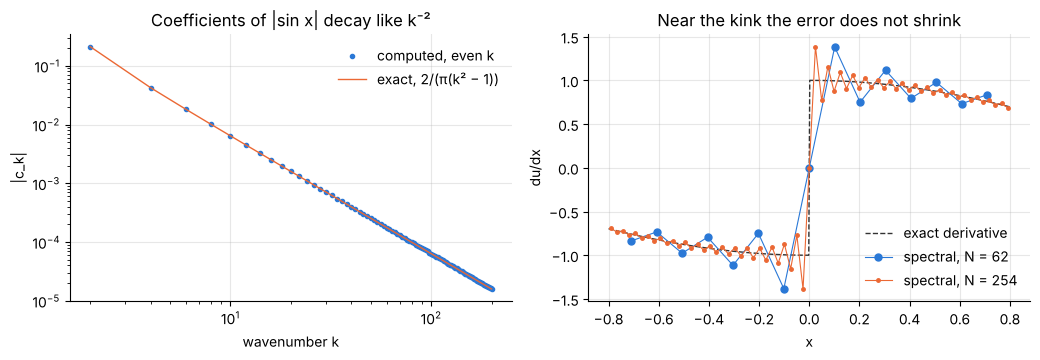

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].loglog(even, np.abs(c[even]), "o", ms=3, label="computed, even k")
axes[0].loglog(even, np.abs(exact_even), color="C1", lw=1, label="exact, 2/(π(k² − 1))")
axes[0].set(xlabel="wavenumber k", ylabel="|c_k|", title="Coefficients of |sin x| decay like k⁻²")
axes[0].legend(frameon=False, loc="upper right")
fine = np.linspace(-0.8, 0.8, 801)
axes[1].plot(fine, rectified_derivative(fine), color="0.2", lw=1, ls="--", label="exact derivative")
for N, marker in ((62, "o"), (254, ".")):
    x = fourier_grid(N)
    centred = np.where(x > np.pi, x - 2 * np.pi, x)             # show the grid points on both sides of x = 0
    near = np.abs(centred) < 0.8
    order = np.argsort(centred[near])
    axes[1].plot(centred[near][order], fft_derivative(rectified(x))[near][order], marker + "-", ms=5, lw=0.8, label=f"spectral, N = {N}")
axes[1].set(xlabel="x", ylabel="du/dx", title="Near the kink the error does not shrink")
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()

The constant error next to the kink can be predicted by hand with the infinite-order weights
$\alpha_k = (-1)^{k+1}/k$ of notebook 1. Near $x = 0$ the data are $u_j \approx |j|h$, and at the
first grid point $u_{1+k} - u_{1-k} = 2h$ for every $k \ge 1$, so the computed derivative is
$2\sum_k \alpha_k = 2\ln 2 = 1.386$ where the exact value is close to 1.

In [5]:
# verify: coefficients against the exact formula, their aliasing error against 3.3, and the errors against the hand predictions
assert abs(decay_order - 2) < 0.01
assert np.abs(c[odd]).max() < 1e-14
aliasing = -4 / np.pi * (np.pi**2 / 6) / 4096**2               # sum of c_(k+mM) over m ≠ 0, with c_k ≈ -2/(πk²)
assert np.abs(c[even] - exact_even - aliasing).max() < 5e-9      # the trapezoidal coefficients are off by the aliasing sum, here to leading order in k/M
assert all(abs(largest[N] - (2 * np.log(2) - 1)) < 0.006 for N in largest)
assert largest[254] > 0.98 * largest[30]                         # no convergence
assert all(abs(middle[N] * N / (middle[30] * 30) - 1) < 0.02 for N in middle)      # away from the kinks: proportional to 1/N

**Answer.** The coefficients decay like $k^{-2}$ (fitted order 2.00) and agree with
$2/(\pi(1 - k^2))$ to $1.3\times10^{-7}$, which is the aliasing error of the 4096-point
trapezoidal rule. The spectral derivative does **not** converge: the largest error is 0.39 at
every $N$ (0.3908, 0.3873, 0.3865, 0.3864), at the grid points next to the kinks, and tends to
$2\ln 2 - 1 = 0.3863$. This is the situation of 3.6. The derivative of $|\sin x|$ is a square
wave of jump 2 times a smooth factor, the interpolant of such a function oscillates near the jump
with an amplitude that refinement does not reduce, and away from the jump the error falls only
like $1/N$ (0.105, 0.051, 0.025, 0.012 near $x = \pi/2$). At the kink itself the method returns
0, the mean of the two one-sided slopes $\pm1$. Differentiating data with a kink gives a
derivative with Gibbs oscillations.

## Exercise 2

The function $u(x) = \dfrac{3}{5 - 4\cos x}$ has the Fourier coefficients $c_k = 2^{-|k|}$.
(a) Where are its singularities, and what decay rate of the spectral derivative error against
$N$ does that predict? Measure the rate and compare. (b) Use the aliasing formula to work out
by hand the discrete amplitudes $\hat v_0/N$ and $\hat v_4/N$ on a grid of $N = 8$ points, and
check both with `np.fft.fft`.

**(a)** The function has poles where $5 - 4\cos x = 0$, that is $\cos x = \tfrac54$. With
$x = iy$, $\cos x = \cosh y = \tfrac54$ gives $y = \pm\ln 2$ (since
$\cosh\ln 2 = \tfrac12(2 + \tfrac12)$). The strip of analyticity has half-width $a = \ln 2$,
consistent with $c_k = 2^{-|k|} = e^{-|k|\ln 2}$, and the error of the spectral derivative should
fall like $N e^{-aN/2} = N\,2^{-N/2}$: a rate of $\tfrac12\ln 2 = 0.347$ per point once the factor
$N$ is divided out, as for $f_3$ in 3.4.

**(b)** By the aliasing formula $\hat v_k/N = \sum_m c_{k+mN}$. With $N = 8$:

$$\frac{\hat v_0}{8} = c_0 + 2\,(c_8 + c_{16} + \dots) = 1 + \frac{2\cdot2^{-8}}{1 - 2^{-8}} = \frac{257}{255},\qquad
\frac{\hat v_4}{8} = 2\,(c_4 + c_{12} + \dots) = \frac{2\cdot2^{-4}}{1 - 2^{-8}} = \frac{32}{255} .$$

In the second sum the wavenumbers $4 + 8m$ are $\dots, -12, -4, 4, 12, \dots$, which come in pairs
of equal size.

(a) fitted decay rate with the factor N divided out: 0.3463   predicted ln(2)/2 = 0.3466
    fitted without dividing out N: 0.3212
    first N with an error below 1e-12: 94
(b) discrete amplitude / N at k = 0: 1.007843137255   257/255 = 1.007843137255
    discrete amplitude / N at k = 4: 0.125490196078    32/255 = 0.125490196078
    for comparison the true coefficients are c_0 = 1 and c_4 = 0.0625


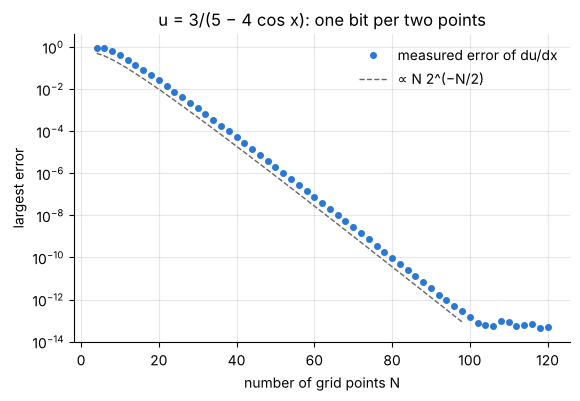

In [6]:
u = lambda x: 3 / (5 - 4 * np.cos(x))
du = lambda x: -12 * np.sin(x) / (5 - 4 * np.cos(x)) ** 2

N_values = np.arange(4, 121, 2)
errors = np.array([derivative_error(u, du, N) for N in N_values])
window = (N_values >= 8) & (N_values <= 90)                    # before rounding errors take over
rate = -np.polyfit(N_values[window], np.log(errors[window] / N_values[window]), 1)[0]
rate_plain = -np.polyfit(N_values[window], np.log(errors[window]), 1)[0]
print(f"(a) fitted decay rate with the factor N divided out: {rate:.4f}   predicted ln(2)/2 = {np.log(2) / 2:.4f}")
print(f"    fitted without dividing out N: {rate_plain:.4f}")
print(f"    first N with an error below 1e-12: {N_values[np.argmax(errors < 1e-12)]}")

amplitudes = np.fft.fft(u(fourier_grid(8))) / 8
print(f"(b) discrete amplitude / N at k = 0: {amplitudes[0].real:.12f}   257/255 = {257 / 255:.12f}")
print(f"    discrete amplitude / N at k = 4: {amplitudes[4].real:.12f}    32/255 = {32 / 255:.12f}")
print(f"    for comparison the true coefficients are c_0 = 1 and c_4 = {2.0**-4}")

fig, ax = plt.subplots()
ax.semilogy(N_values, errors, "o", ms=4, label="measured error of du/dx")
ax.semilogy(N_values[:48], 0.5 * N_values[:48] * 2.0 ** (-N_values[:48] / 2), "--", color="0.4", lw=1, label="∝ N 2^(−N/2)")
ax.set(xlabel="number of grid points N", ylabel="largest error", title="u = 3/(5 − 4 cos x): one bit per two points")
ax.legend(frameon=False, loc="upper right");

In [7]:
# verify: the pole, the given coefficients, the rate and the two aliased amplitudes
assert abs(5 - 4 * np.cos(1j * np.log(2))) < 1e-14                               # pole at x = i ln 2
k = np.fft.fftfreq(128, 1 / 128)
assert np.abs(fourier_coefficients(u, 128) - 2.0 ** -np.abs(k)).max() < 1e-13    # c_k = 2^-|k|
assert abs(rate / (np.log(2) / 2) - 1) < 0.01
assert abs(amplitudes[0] - 257 / 255) < 1e-14 and abs(amplitudes[4] - 32 / 255) < 1e-14

**Answer.** (a) The singularities are simple poles at $x = \pm i\ln 2$ (and their $2\pi$-periodic
copies), at distance $a = \ln 2 = 0.693$ from the real axis. The predicted error is
$\propto N\,2^{-N/2}$, a rate of 0.3466 per point, and the measured rate is 0.3463. Every two extra
grid points halve the error, and an error of $10^{-12}$ takes 94 points. (Without dividing out the factor
$N$ the fit gives 0.32, which shows that the factor is real.) (b) $\hat v_0/N = 257/255 = 1.00784$
and $\hat v_4/N = 32/255 = 0.12549$, both confirmed by `np.fft.fft` to rounding. The Nyquist
amplitude is twice the true coefficient $c_4 = 0.0625$, because $c_{-4}$ is aliased onto it at
full strength: on a coarse grid the highest modes are the least trustworthy.

## Exercise 3

A step can be replaced by a smooth ramp: $u(x) = \tanh\big(\sin(x)/\delta\big)$ tends to the
square wave as $\delta \to 0$. The function $\tanh z$ has its nearest singularities at
$z = \pm i\pi/2$. For $\delta = 0.1$ find the distance $a$ of the nearest singularity of $u$
from the real axis and predict the decay rate of the spectral derivative error. Measure the
rate for even $N$ between 40 and 300 (divide the error by $N$ before fitting, as in 3.4), then search even $N$ up to 800 for the smallest one
that gives an error below $10^{-8}$. How does that $N$ change if $\delta$ is halved to 0.05?

The singularities of $u$ are where $\sin(x)/\delta = \pm i\pi/2$. With $x = iy$,
$\sin(iy) = i\sinh y$, so $\sinh y = \pi\delta/2$ and

$$a = \mathrm{arcsinh}\,\frac{\pi\delta}{2} \approx \frac{\pi\delta}{2}\quad\text{for small }\delta .$$

For $\delta = 0.1$ this is $a = 0.1564$, and the predicted rate is $a/2 = 0.0782$ per point. The
singularities are simple poles, as for $f_3$ in 3.4, so the error of the derivative carries a
factor $N$ that is divided out before fitting. The strip width is proportional to $\delta$:
halving $\delta$ should double the number of points.

δ = 0.1: a = 0.1564, predicted rate a/2 = 0.0782, measured for N = 40..300: 0.0782, smallest N with an error below 1e-8: 312
δ = 0.05: a = 0.0785, predicted rate a/2 = 0.0392, measured for N = 40..300: 0.0393, smallest N with an error below 1e-8: 642


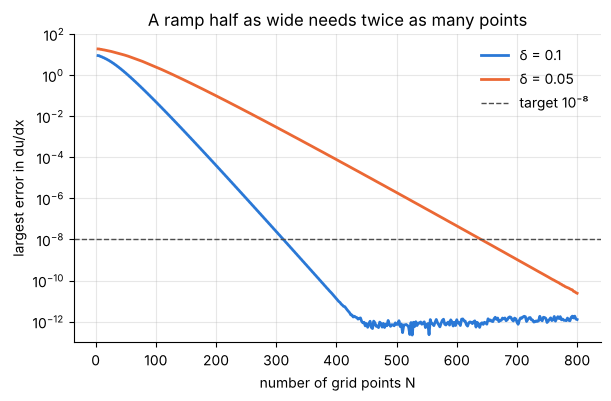

In [8]:
def ramp(delta):
    """The smoothed square wave tanh(sin(x)/δ) and its exact derivative."""
    return (lambda x: np.tanh(np.sin(x) / delta),
            lambda x: np.cos(x) / (delta * np.cosh(np.sin(x) / delta) ** 2))

N_search = np.arange(4, 801, 2)
ramp_results = {}
for delta in (0.1, 0.05):
    u, du = ramp(delta)
    err = np.array([derivative_error(u, du, N) for N in N_search])
    a = np.arcsinh(np.pi * delta / 2)
    window = (N_search >= 40) & (N_search <= 300)
    rate = -np.polyfit(N_search[window], np.log(err[window] / N_search[window]), 1)[0]
    N_needed = int(N_search[np.argmax(err < 1e-8)])
    ramp_results[delta] = (err, a, rate, N_needed)
    print(f"δ = {delta}: a = {a:.4f}, predicted rate a/2 = {a / 2:.4f}, measured for N = 40..300: {rate:.4f}, "
          f"smallest N with an error below 1e-8: {N_needed}")

fig, ax = plt.subplots(figsize=(6.8, 4))
for delta, (err, a, rate, N_needed) in ramp_results.items():
    ax.semilogy(N_search, err, label=f"δ = {delta}")
ax.axhline(1e-8, color="0.3", lw=1, ls="--", label="target 10⁻⁸")
ax.set(xlabel="number of grid points N", ylabel="largest error in du/dx", ylim=(1e-13, 1e2),
       title="A ramp half as wide needs twice as many points")
ax.legend(frameon=False, loc="upper right");

In [9]:
# verify: the pole position, the measured rates against a/2, and the scaling of N with the strip width
for delta, (err, a, rate, N_needed) in ramp_results.items():
    assert abs(np.cosh(np.sin(1j * a) / delta)) < 1e-14          # tanh = sinh/cosh has a pole where cosh vanishes
    assert abs(rate / (a / 2) - 1) < 0.01
    assert (err < 1e-8).any() and np.all(err[N_search >= N_needed][:20] < 1e-8)   # the target is reached, and the error stays below it
a_wide, a_narrow = ramp_results[0.1][1], ramp_results[0.05][1]
N_wide, N_narrow = ramp_results[0.1][3], ramp_results[0.05][3]
assert (N_wide, N_narrow) == (312, 642)
assert abs((N_narrow / N_wide) / (a_wide / a_narrow) - 1) < 0.05

**Answer.** For $\delta = 0.1$ the nearest singularities are at $x = \pm i\,\mathrm{arcsinh}(\pi\delta/2)$,
so $a = 0.1564$, and the predicted error is $\propto N e^{-0.0782N}$. The measured rate for
$N = 40$ to 300 is 0.0782. The error first drops below $10^{-8}$ at $N = 312$. For
$\delta = 0.05$ the strip is half as wide ($a = 0.0785$), the rate is 0.0393 (predicted 0.0392), and
$N = 642$ points are needed, 2.06 times as many. A ramp makes spectral accuracy possible again, but the price is
set by its width: the grid must resolve the ramp, and the number of points grows like
$1/\delta$. Compare the true step, for which no $N$ is enough.

## Exercise 4

Replace the cycloidal rise of 3.7 by the simple harmonic rise
$y = \tfrac12\big(1 - \cos(\pi\theta/\beta)\big)$, with the same angles ($\beta = 120°$, dwell
to $180°$, mirror-image return to $300°$, dwell to $360°$). Which derivative of $y$ jumps?
Predict and measure the convergence order of the spectral **velocity** $dy/d\theta$ for $N$
from 12 to 240 in steps of 4. What happens to the computed acceleration?

Differentiate the rise: the velocity is $\dfrac{\pi}{2\beta}\sin\dfrac{\pi\theta}{\beta}$, which is zero
at both ends of the rise and joins the dwells continuously. The acceleration is
$\dfrac{\pi^2}{2\beta^2}\cos\dfrac{\pi\theta}{\beta}$, which is $\pm\pi^2/2\beta^2 = \pm1.125$ at the ends
and zero in the dwells. So the **second** derivative jumps: $p = 2$. The table predicts
$N^{-(p-\nu)}$: order 1 for the velocity ($\nu = 1$) and order 0, no convergence, for the
acceleration ($\nu = 2$).

velocity:     observed order 1.00 (predicted 1), error 6.9e-02 at N = 12, 3.7e-03 at N = 240
acceleration: observed order 0.00 (predicted 0), error between 0.560 and 0.586
jump of the acceleration 1.1250, half of it 0.5625


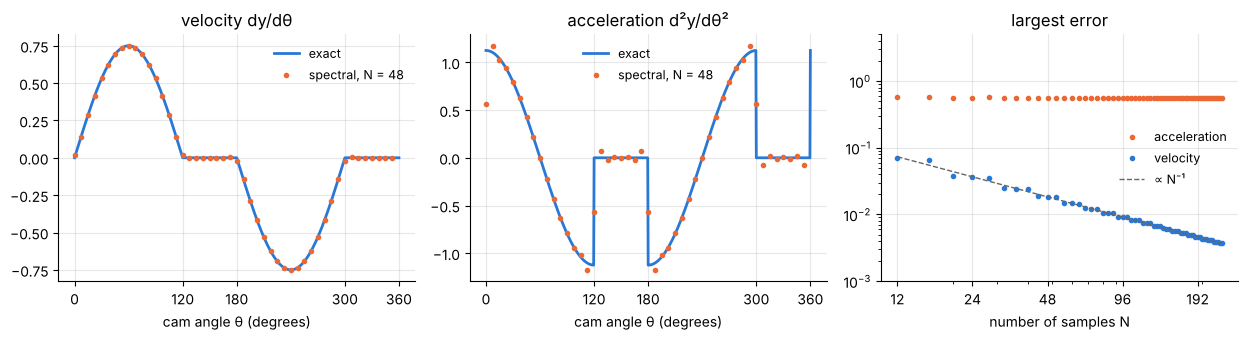

In [10]:
beta = 2 * np.pi / 3

def piecewise(theta, rise, top=0.0):
    """Rise over β, dwell at `top` to 180°, mirror-image return to 300°, dwell at 0 to 360°."""
    t = np.mod(theta, 2 * np.pi)
    return np.where(t < beta, rise(t), np.where(t < np.pi, top, np.where(t < np.pi + beta, top - rise(t - np.pi), 0.0)))

harmonic_lift = lambda theta: piecewise(theta, lambda s: 0.5 * (1 - np.cos(np.pi * s / beta)), top=1.0)
harmonic_velocity = lambda theta: piecewise(theta, lambda s: 0.5 * np.pi / beta * np.sin(np.pi * s / beta))
harmonic_acceleration = lambda theta: piecewise(theta, lambda s: 0.5 * (np.pi / beta) ** 2 * np.cos(np.pi * s / beta))
jump = 0.5 * (np.pi / beta) ** 2

N_cam = np.arange(12, 241, 4)
velocity_errors = np.array([derivative_error(harmonic_lift, harmonic_velocity, N) for N in N_cam])
acceleration_errors = np.array([derivative_error(harmonic_lift, harmonic_acceleration, N, order=2) for N in N_cam])
velocity_order = -np.polyfit(np.log(N_cam), np.log(velocity_errors), 1)[0]
acceleration_order = -np.polyfit(np.log(N_cam), np.log(acceleration_errors), 1)[0]
print(f"velocity:     observed order {velocity_order:.2f} (predicted 1), error {velocity_errors[0]:.1e} at N = 12, {velocity_errors[-1]:.1e} at N = 240")
print(f"acceleration: observed order {acceleration_order:.2f} (predicted 0), error between {acceleration_errors.min():.3f} and {acceleration_errors.max():.3f}")
print(f"jump of the acceleration {jump:.4f}, half of it {jump / 2:.4f}")

degrees = np.linspace(0, 360, 721)
theta = fourier_grid(48)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.5))
axes[0].plot(degrees, harmonic_velocity(np.radians(degrees)), label="exact")
axes[0].plot(np.degrees(theta), fft_derivative(harmonic_lift(theta)), "o", ms=3, color="C1", label="spectral, N = 48")
axes[0].set(xlabel="cam angle θ (degrees)", title="velocity dy/dθ", xticks=[0, 120, 180, 300, 360])
axes[0].legend(frameon=False, loc="upper right", fontsize=9)
axes[1].plot(degrees, harmonic_acceleration(np.radians(degrees)), label="exact")
axes[1].plot(np.degrees(theta), fft_derivative(harmonic_lift(theta), 2), "o", ms=3, color="C1", label="spectral, N = 48")
axes[1].set(xlabel="cam angle θ (degrees)", title="acceleration d²y/dθ²", xticks=[0, 120, 180, 300, 360])
axes[1].legend(frameon=False, loc="upper center", fontsize=9)
axes[2].loglog(N_cam, acceleration_errors, "o", ms=3, color="C1", label="acceleration")
axes[2].loglog(N_cam, velocity_errors, "o", ms=3, color="C0", label="velocity")
axes[2].loglog(N_cam, 0.88 / N_cam, "--", color="0.4", lw=1, label="∝ N⁻¹")
axes[2].set(xlabel="number of samples N", title="largest error", ylim=(1e-3, 5))
axes[2].set_xticks([12, 24, 48, 96, 192], labels=["12", "24", "48", "96", "192"])
axes[2].tick_params(axis="x", which="minor", labelbottom=False)
axes[2].legend(frameon=False, loc="center right", fontsize=9)
fig.tight_layout()

In [11]:
# verify: the typed-in derivatives against difference quotients, then the two predicted orders
check, step = np.linspace(0.05, 6.2, 40), 1e-4
assert np.abs((harmonic_lift(check + step) - harmonic_lift(check - step)) / (2 * step) - harmonic_velocity(check)).max() < 1e-6
assert np.abs((harmonic_velocity(check + step) - harmonic_velocity(check - step)) / (2 * step) - harmonic_acceleration(check)).max() < 1e-6
assert np.isclose(harmonic_lift(np.pi / 2 + 0.7), 1.0) and np.isclose(harmonic_lift(np.pi + beta / 2), 0.5)
assert abs(velocity_order - 1) < 0.1
assert abs(acceleration_order) < 0.05 and np.abs(acceleration_errors / (jump / 2) - 1).max() < 0.05

**Answer.** The second derivative, the acceleration, jumps by $\pi^2/2\beta^2 = 1.125$ at each
end of the rise and of the return, so $p = 2$. The spectral velocity converges with the
predicted order 1 (measured 1.00): its error falls from $6.9\times10^{-2}$ at $N = 12$ to
$3.7\times10^{-3}$ at $N = 240$. The computed acceleration does not converge at all. Its largest
error stays between 0.56 and 0.59 for every $N$, which is half the jump (0.5625): at a jump
that falls on a grid point, as $\theta = 0$ and $180°$ always do, the method returns the mean of
the two sides, and next to it the result oscillates as in the Gibbs phenomenon (middle panel).
This cam is worse than the cycloidal one of 3.7 by exactly one order, for the numerical method
as for the machine: the acceleration jump that makes the spectral method fail is the same jump
that makes the follower rattle.

## Exercise 5

The product $u(x) = \sin 5x\,\cos 7x$ is band-limited. Which wavenumbers does it contain?
Find, by reasoning and then by experiment with even $N$ from 4 to 40, the smallest $N$ from
which `fft_derivative` is exact for every larger even $N$. Explain why $N = 24$ fails
although $f_4$ in 3.4 was already exact at $N = 16$.

The product formula $\sin A\cos B = \tfrac12\big(\sin(A + B) + \sin(A - B)\big)$ gives

$$u(x) = \tfrac12\sin 12x - \tfrac12\sin 2x ,$$

so the function contains the wavenumbers $\pm2$ and $\pm12$ and is band-limited with $K = 12$,
although neither factor suggests it. The table promises exactness for $N > 2K = 24$, so the
candidate answer is $N = 26$. The case $N = 2K = 24$ puts wavenumber 12 at the Nyquist limit and
has to be looked at separately.

In [12]:
product = lambda x: np.sin(5 * x) * np.cos(7 * x)
product_derivative = lambda x: 5 * np.cos(5 * x) * np.cos(7 * x) - 7 * np.sin(5 * x) * np.sin(7 * x)

c = fourier_coefficients(product, 64)
k = np.fft.fftfreq(64, 1 / 64).astype(int)
print("wavenumbers present:", sorted(k[np.abs(c) > 1e-12].tolist()), " with |c_k| =", np.round(np.abs(c[np.abs(c) > 1e-12]), 12))

N_even = np.arange(4, 41, 2)
product_errors = np.array([derivative_error(product, product_derivative, N) for N in N_even])
print("largest error of fft_derivative:")
for row in np.array_split(np.arange(len(N_even)), 4):
    print("   " + "   ".join(f"N = {N_even[i]:2d}: {product_errors[i]:7.1e}" for i in row))
N_exact = int(N_even[np.argmax(np.cumsum((product_errors > 1e-10)[::-1])[::-1] == 0)])
print(f"exact for every even N from {N_exact}")
print(f"N = 24: largest sample of sin 12x on the grid {np.abs(np.sin(12 * fourier_grid(24))).max():.1e};  "
      f"N = 16: samples of cos 8x {np.cos(8 * fourier_grid(16))[:4].round(12)} ...")

wavenumbers present: [-12, -2, 2, 12]  with |c_k| = [0.25 0.25 0.25 0.25]
largest error of fft_derivative:
   N =  4: 7.0e+00   N =  6: 6.0e+00   N =  8: 6.0e+00   N = 10: 5.0e+00   N = 12: 6.0e+00
   N = 14: 7.0e+00   N = 16: 8.0e+00   N = 18: 9.0e+00   N = 20: 1.0e+01   N = 22: 1.1e+01
   N = 24: 6.0e+00   N = 26: 5.6e-14   N = 28: 4.3e-14   N = 30: 5.0e-14   N = 32: 6.1e-14
   N = 34: 4.7e-14   N = 36: 5.7e-14   N = 38: 8.3e-14   N = 40: 2.1e-14
exact for every even N from 26
N = 24: largest sample of sin 12x on the grid 9.8e-15;  N = 16: samples of cos 8x [ 1. -1.  1. -1.] ...


In [13]:
# verify: against the product formula and the hand reasoning for N = 24
x = fourier_grid(64)
assert np.abs(product(x) - 0.5 * (np.sin(12 * x) - np.sin(2 * x))).max() < 1e-12
assert sorted(k[np.abs(c) > 1e-12].tolist()) == [-12, -2, 2, 12] and np.allclose(np.abs(c[np.abs(c) > 1e-12]), 0.25)
assert N_exact == 26 and product_errors[N_even >= 26].max() < 1e-11 and product_errors[N_even < 26].min() > 1
x = fourier_grid(24)                                           # on 24 points only -½ sin 2x is seen; the lost term has derivative 6 cos 12x = 6
assert np.abs(fft_derivative(product(x)) + np.cos(2 * x)).max() < 1e-12 and abs(product_errors[N_even == 24][0] - 6) < 1e-12

**Answer.** $u = \tfrac12\sin 12x - \tfrac12\sin 2x$ contains the wavenumbers $\pm2$ and $\pm12$.
`fft_derivative` is exact (errors below $10^{-13}$) for every even $N \ge 26$, and wrong by an
error of order 5 to 11 for every smaller $N$. At $N = 24$ the error is exactly 6. There,
wavenumber 12 is the Nyquist wavenumber and the term is a **sine**: $\sin 12x_j = \sin(j\pi) = 0$
at every grid point, so the samples contain no trace of it, while its derivative
$6\cos 12x_j = 6$ is as large as it can be there. The function $f_4$ of 3.4 had a **cosine** at its
Nyquist wavenumber: $\cos 8x_j = (-1)^j$ is visible on 16 points, and its derivative is zero at
the grid points, which is what the Nyquist rule returns. A grid with $N = 2K$ carries only the
cosine half of its highest wavenumber. The safe rule is $N > 2K$.